# 04 — Portfolio Optimization

Five construction rules plus one cautionary experiment, all long-only and fully invested. Each month-end uses only information up to that date (covariance forecasts from notebook 03).

| Rule | Objective | Constraints | Input |
|---|---|---|---|
| Equal Weight | $w_i = 1/12$ | — | — |
| 60/40 | fixed: SPY 42, VGK 12, EWJ 6 / EUR core 20, IEF 15, JGB 5 | — | — |
| Minimum Variance | $\min_w w^\top\Sigma w$ | $0 \le w_i \le 30\%$ | GARCH-CCC $\Sigma$ |
| Risk Parity | $w_i(\Sigma w)_i = \tfrac1N w^\top\Sigma w$ | long-only (no cap — a cap would break equal risk) | GARCH-CCC $\Sigma$ |
| CVaR | $\min_w \mathrm{CVaR}_{95\%}(-Rw)$, Rockafellar–Uryasev LP | $0 \le w_i \le 30\%$ | last 156 weekly returns as scenarios |
| *MV-hist (cautionary)* | $\max_w \mu^\top w - \tfrac{\gamma}{2}w^\top\Sigma w$, $\gamma=5$ | $0 \le w_i \le 30\%$ | rolling 3-year historical mean $\mu$ |

**Solvers** are implemented with numpy only (`src/optimize.py`): an OSQP-style ADMM for the QP/LP problems and cyclical coordinate descent for risk parity (Griveau-Billion, Richard & Roncalli 2013). This notebook builds the **target weights**; drift, turnover, costs and performance are notebook 05.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src import optimize as O, risk as K, universe as U

pd.set_option("display.float_format", "{:.3f}".format)
plt.rcParams["figure.figsize"] = (11, 4)
PROC = ROOT / "data" / "processed"
weekly = pd.read_csv(PROC / "asset_returns_eur_weekly.csv", index_col=0, parse_dates=True)[U.ASSETS].dropna()
fc = K.load_forecasts(PROC / "cov_forecasts.npz")          # written by notebook 03
EST, CAP = "GARCH-CCC", 0.30
paths = O.weight_paths(fc, weekly, EST, cap=CAP, cache_dir=PROC / "weights")  # ~6 min on first run, cached afterwards
sleeve = pd.Series(U.SLEEVE)
print(f"{len(fc['dates'])} rebalancing dates {fc['dates'][0]:%Y-%m} → {fc['dates'][-1]:%Y-%m}; covariance input: {EST}")

197 rebalancing dates 2010-04 → 2026-08; covariance input: GARCH-CCC


## 1. Solver checks on the latest covariance forecast

In [2]:
k = len(fc["dates"]) - 1
t_snap = fc["dates"][k]
S = fc["cov1w"][EST][k] * 52                      # annualised
scen = weekly.loc[:t_snap].to_numpy()[-156:]
n = len(U.ASSETS)
w_qp = O.solve_qp(S / np.mean(np.diag(S)), np.zeros(n), np.ones((1, n)), np.ones(1), np.ones(1)).x
w_mv = O.min_variance(S, CAP); g = S @ w_mv; free = (w_mv > 1e-6) & (w_mv < CAP - 1e-6)
w_rp = O.risk_parity(S); w_cv, cv = O.min_cvar(scen, 0.95, CAP)
rng = np.random.default_rng(0)
rand = rng.dirichlet(np.ones(n), 20000); rand = rand[(rand <= CAP).all(axis=1)]
pd.Series({
    "GMV: ADMM vs closed form, max |Δw|": np.abs(w_qp - O.gmv_unconstrained(S)).max(),
    "MinVar KKT: spread of (Σw)_i over free assets": np.ptp(g[free]) if free.any() else 0.0,
    "Risk parity: spread of risk contributions": np.ptp(O.risk_contributions(w_rp, S)),
    "CVaR optimum (weekly loss)": cv,
    f"best of {len(rand)} random capped portfolios": min(O.cvar(scen @ w) for w in rand),
}, name=f"checks at {t_snap:%Y-%m-%d}").to_frame()

,checks at 2026-08-31
"GMV: ADMM vs closed form, max |Δw|",0.000
MinVar KKT: spread of (Σw)_i over free assets,0.000
Risk parity: spread of risk contributions,0.000
CVaR optimum (weekly loss),0.005
best of 15313 random capped portfolios,0.007


## 2. Snapshot: target weights for September 2026

In [3]:
budget = np.array([0.25 / (sleeve == sleeve[a]).sum() for a in U.ASSETS])
snap = pd.DataFrame({m: paths[m].loc[t_snap] for m in O.METHODS})
snap["RP-sleeve"] = O.risk_parity(S, budget)
def describe(w):
    w = np.asarray(w, float)
    return {"ex-ante vol %": 100 * np.sqrt(w @ S @ w), "weekly CVaR95 % (3y hist.)": 100 * O.cvar(scen @ w),
            "effective N": 1 / np.sum(w ** 2), "max weight %": 100 * w.max()}
stats = pd.DataFrame({m: describe(snap[m]) for m in snap.columns})
(snap * 100).round(1).pipe(lambda d: pd.concat([d, stats.round(2)], keys=["weight %", "risk"]))

EW  60/40  ...  MV-hist  RP-sleeve
weight % SPY                         8.300 42.000  ...   30.000      2.700
         VGK                         8.300 12.000  ...   30.000      3.400
         EWJ                         8.300  6.000  ...   10.000      2.000
         SHY                         8.300  0.000  ...    0.000     38.600
         IEF                         8.300 15.000  ...    0.000      6.400
         TLT                         8.300  0.000  ...    0.000      2.800
         EUR_CORE7_10_SYN            8.300 20.000  ...    0.000      6.300
         JGB7_10_SYN                 8.300  5.000  ...    0.000     11.100
         LQD                         8.300  0.000  ...    0.000      7.600
         HYG                         8.300  0.000  ...    0.000     12.600
         GLD                         8.300  0.000  ...   30.000      3.200
         DBC                         8.300  0.000  ...    0.000      3.200
risk     ex-ante vol %               5.520  8.050  ...   11.020      2.560
         weekly CVaR95 % (3y hist.)  1.860  2.670  ...    3.770      0.820
         effective N                12.000  3.860  ...    3.570      5.090
         max weight %                8.330 42.000  ...   30.000     38.640

[16 rows x 7 columns]

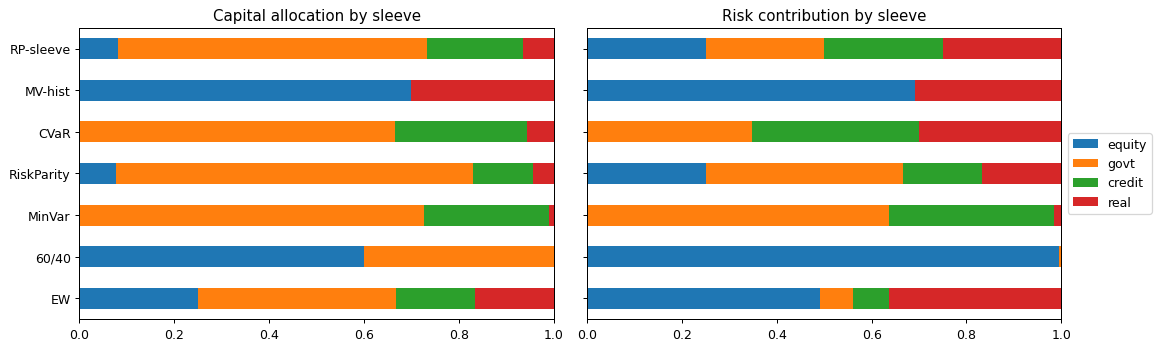

In [4]:
rc = pd.DataFrame({m: O.risk_contributions(snap[m].to_numpy(), S) for m in snap.columns}, index=U.ASSETS)
rc_sleeve = rc.groupby(sleeve).sum().T[["equity", "govt", "credit", "real"]]
wt_sleeve = snap.groupby(sleeve).sum().T[["equity", "govt", "credit", "real"]]
fig, ax = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
wt_sleeve.plot.barh(stacked=True, ax=ax[0], title="Capital allocation by sleeve", legend=False)
rc_sleeve.plot.barh(stacked=True, ax=ax[1], title="Risk contribution by sleeve")
ax[1].legend(loc="center left", bbox_to_anchor=(1, 0.5)); plt.tight_layout(); plt.show()

**Asset-level vs sleeve-level risk parity.** With 12 assets of which five are government bonds, equal risk *per asset* hands most of the budget to bonds, and hedged SHY (volatility ≈ 1.5%) needs a huge weight to contribute 1/12 of the risk. Sleeve-level budgets (25% each to equity, government bonds, credit, real assets, split equally inside a sleeve) give a more balanced portfolio. The backtest keeps the asset-level version as the textbook rule; RP-sleeve is reported as a robustness variant.

## 3. How much do the caps drive the result?

In [5]:
rows = {}
for cap in [0.20, 0.30, 0.50, 1.00]:
    w = O.min_variance(S, cap); wc, _ = O.min_cvar(scen, 0.95, cap)
    rows[f"cap {cap:.0%}"] = {"MinVar vol %": 100 * np.sqrt(w @ S @ w), "MinVar eff. N": 1 / (w ** 2).sum(),
                              "MinVar top holding": f"{U.ASSETS[w.argmax()]} {w.max():.0%}",
                              "CVaR weekly %": 100 * O.cvar(scen @ wc), "CVaR eff. N": 1 / (wc ** 2).sum(),
                              "CVaR top holding": f"{U.ASSETS[wc.argmax()]} {wc.max():.0%}"}
pd.DataFrame(rows).T

,MinVar vol %,MinVar eff. N,MinVar top holding,CVaR weekly %,CVaR eff. N,CVaR top holding
cap 20%,2.176,5.418,HYG 20%,0.704,5.529,JGB7_10_SYN 20%
cap 30%,1.854,3.889,JGB7_10_SYN 30%,0.538,3.800,SHY 30%
cap 50%,1.460,2.861,SHY 50%,0.385,2.516,SHY 50%
cap 100%,0.868,1.089,SHY 96%,0.324,1.528,SHY 79%


## 4. Target weights through time (by sleeve)

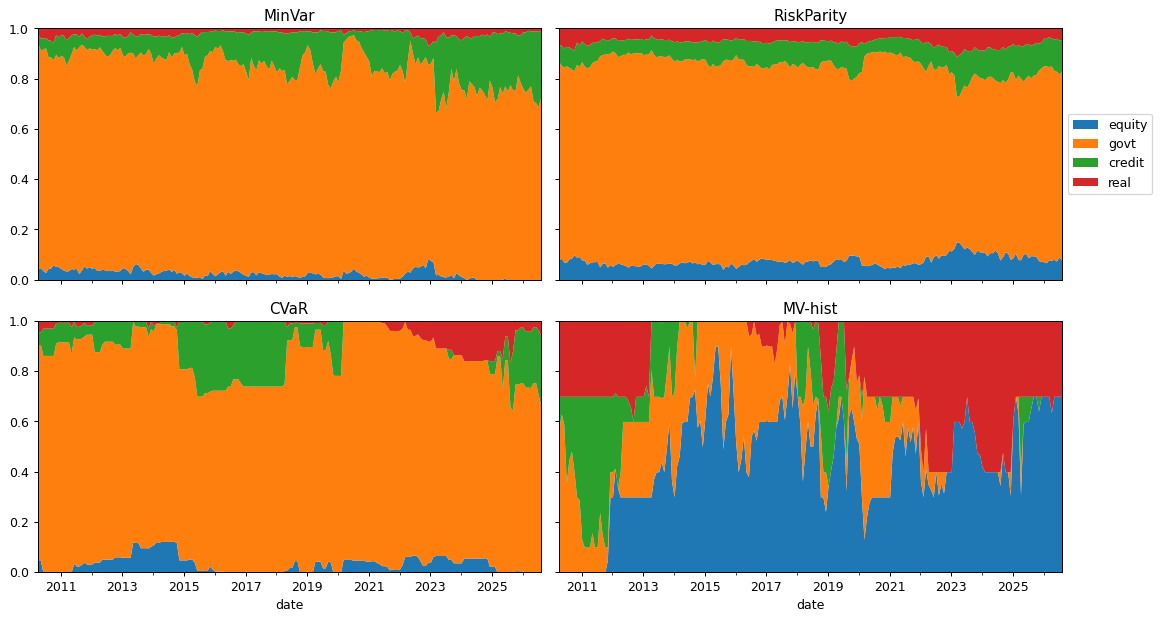

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True, sharey=True)
for ax, m in zip(axes.ravel(), ["MinVar", "RiskParity", "CVaR", "MV-hist"]):
    paths[m].T.groupby(sleeve).sum().T[["equity", "govt", "credit", "real"]].plot.area(ax=ax, title=m, legend=False, lw=0)
    ax.set_ylim(0, 1)
axes[0, 1].legend(loc="center left", bbox_to_anchor=(1, 0.5)); plt.tight_layout(); plt.show()

In [7]:
def path_stats(w):
    to = w.diff().abs().sum(axis=1).iloc[1:] / 2
    sl = w.T.groupby(sleeve).sum().T.mean()
    return {"avg one-way turnover / month %": 100 * to.mean(), "max monthly turnover %": 100 * to.max(),
            "avg effective N": (1 / (w ** 2).sum(axis=1)).mean(),
            **{f"avg {s} %": 100 * sl.get(s, 0) for s in ["equity", "govt", "credit", "real"]}}
pd.DataFrame({m: path_stats(paths[m]) for m in O.METHODS}).T.round(1)

,avg one-way turnover / month %,max monthly turnover %,avg effective N,avg equity %,avg govt %,avg credit %,avg real %
EW,0.000,0.000,12.000,25.000,41.700,16.700,16.700
60/40,0.000,0.000,3.900,60.000,40.000,0.000,0.000
MinVar,5.900,23.800,4.200,2.400,82.500,13.000,2.100
RiskParity,3.900,19.200,4.200,7.600,77.900,9.000,5.500
CVaR,2.900,33.200,4.000,3.400,83.500,9.900,3.200
MV-hist,11.100,54.500,3.700,45.300,19.900,10.700,24.000


Turnover here is target-to-target and ignores drift between rebalances; notebook 05 measures the turnover actually traded.

## 5. Cautionary experiment: historical means as expected returns

Mean-variance optimisation is an error maximiser: small changes in $\hat\mu$ move the solution to a corner. Rolling 3-year means are noisy estimates of expected returns, so the weights jump between whichever assets happened to perform best recently.

Largest holding changed 106 times in 197 months; turnover 11.1% vs 5.9% for MinVar per month


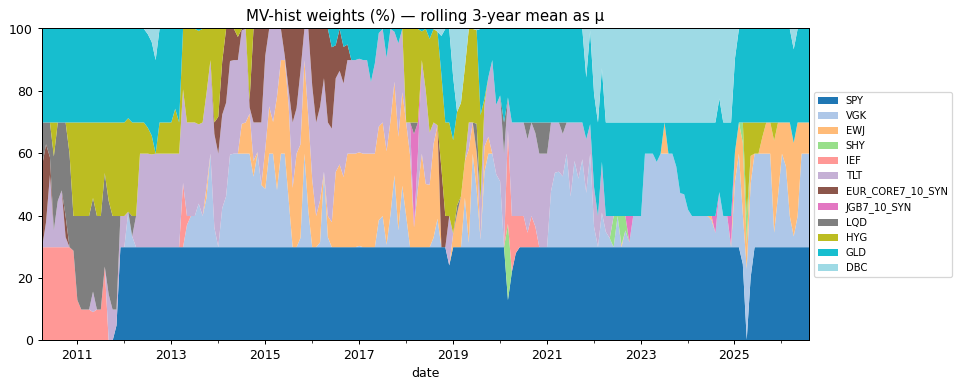

In [8]:
top = paths["MV-hist"].idxmax(axis=1)
switches = (top != top.shift()).sum() - 1
ax = (paths["MV-hist"] * 100).plot.area(lw=0, colormap="tab20", title="MV-hist weights (%) — rolling 3-year mean as μ", figsize=(11, 4.5))
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=8); ax.set_ylim(0, 100); plt.show()
print(f"Largest holding changed {switches} times in {len(top)} months; "
      f"turnover {100 * (paths['MV-hist'].diff().abs().sum(axis=1).iloc[1:] / 2).mean():.1f}% vs "
      f"{100 * (paths['MinVar'].diff().abs().sum(axis=1).iloc[1:] / 2).mean():.1f}% for MinVar per month")

## Takeaways

* **Solvers verified on real inputs:** ADMM matches the closed-form GMV, min-variance satisfies KKT, risk contributions are equal to machine precision, and the CVaR optimum (0.54% weekly) beats the best of ~15k random capped portfolios (0.7%).
* **Risk-based rules are bond portfolios.** MinVar, Risk Parity and CVaR hold 78–84% government bonds on average and have ex-ante volatility of ~2% p.a. (Sept 2026) vs 5.5% for EW and 8.1% for 60/40. Hedged short Treasuries (SHY) and hedged JGBs are the cheapest risk in a EUR portfolio.
* **Constraints, not the optimiser, decide much of the answer.** Without a cap MinVar puts 96% in SHY; with 30% it spreads across SHY, JGB, HYG, IEF. Effective N rises from 1.1 to 3.9.
* **Risk parity across 12 assets is really risk parity across asset classes with five government-bond votes.** Asset-level RP gives 44% to SHY and 8% to equities; sleeve-level budgets change little because the low-volatility asset inside the bond sleeve still needs a large weight.
* **Historical means make MV unusable:** the largest holding changed 106 times in 197 months and turnover is ~2× MinVar (11% vs 6% one-way per month), before costs.
* **Implication for notebook 05:** comparing raw returns of a 2%-vol and an 8%-vol portfolio is meaningless. The backtest reports risk-adjusted metrics and adds **volatility-targeted versions** (scaled to the 60/40 ex-ante volatility, financed at the EUR overnight rate) — the way risk parity is run in practice.